# 02 · Análise exploratória com foco no negócio

**Tech Challenge Fase 1 · NPS Preditivo**

Esta análise responde às quatro perguntas do desafio, escrita para **um(a) gerente de operações
que não precisa saber estatística**:

1. Quais fatores parecem mais críticos para a satisfação?
2. O que mais gera detratores?
3. Existe algum "ponto de ruptura" na experiência do cliente?
4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Cada gráfico vem com um quadro **"Leitura para a operação"** que traduz o número em decisão. Os
testes estatísticos aparecem em células próprias para quem quiser conferir, mas a conclusão não
depende de entendê-los.

Todos os gráficos são salvos em `reports/figures/` para serem usados na apresentação.

In [1]:
import sys
from pathlib import Path

# Localiza a raiz do projeto (a pasta que contém src/) para importar o código compartilhado,
# não importa de onde o notebook seja aberto.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.tree import DecisionTreeRegressor

from src import config, data_prep
from src import visualization as viz

viz.apply_style()
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

df = data_prep.load_processed_data()
print(f"{len(df):,} pedidos carregados da base tratada")

2,500 pedidos carregados da base tratada


## 0. Ponto de partida: como está a satisfação hoje?

In [2]:
nps_value = data_prep.nps_index(df["nps_score"])
shares = df["nps_category"].value_counts(normalize=True).mul(100)

print(f"NPS da base: {nps_value}")
print(f"Nota média: {df['nps_score'].mean():.2f} | mediana: {df['nps_score'].median():.1f}")
print(f"Notas zero: {(df['nps_score'] == 0).sum()} | notas dez: {(df['nps_score'] == 10).sum()}")
shares.round(1)

NPS da base: -80.0
Nota média: 4.38 | mediana: 4.4
Notas zero: 158 | notas dez: 42


nps_category
detrator   84.40
neutro     11.20
promotor    4.40
Name: proportion, dtype: float64

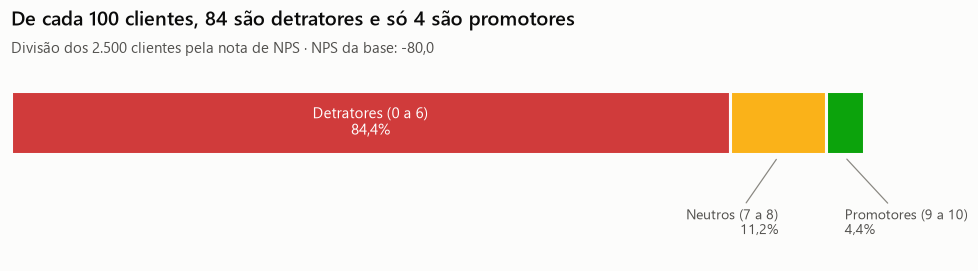

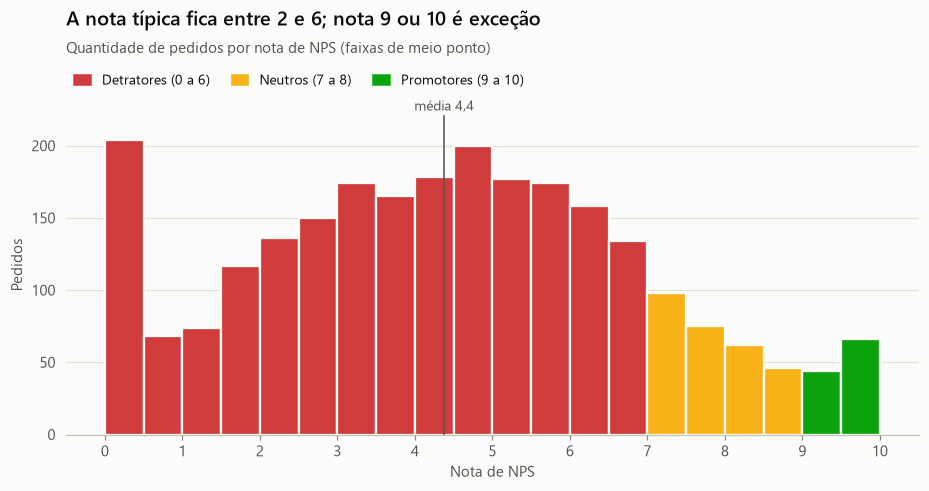

In [3]:
fig = viz.plot_nps_scale(
    df,
    title="De cada 100 clientes, 84 são detratores e só 4 são promotores",
    subtitle=f"Divisão dos 2.500 clientes pela nota de NPS · NPS da base: {viz.fmt_number(nps_value)}",
)
viz.save_figure(fig, "01_nps_regua.png")
plt.show()

fig = viz.plot_score_distribution(
    df,
    title="A nota típica fica entre 2 e 6; nota 9 ou 10 é exceção",
    subtitle="Quantidade de pedidos por nota de NPS (faixas de meio ponto)",
)
viz.save_figure(fig, "02_nps_distribuicao.png")
plt.show()

> **Leitura para a operação:** o NPS da base é **-80**. Para comparação, NPS abaixo de zero já
> significa que há mais clientes falando mal do que bem da empresa. Aqui, **84 de cada 100
> clientes são detratores**, a nota média é 4,4 e 158 clientes deram nota zero. Insatisfação não é
> exceção, é a experiência padrão. Por isso a pergunta não é "quem são os poucos insatisfeitos",
> e sim **"o que separa os poucos satisfeitos de todo o resto"**.

## 1. Quais fatores parecem mais críticos para a satisfação?

Começamos medindo o quanto cada variável "anda junto" com a nota. A **correlação** vai de -1 a +1:

- perto de **-1**: quando a variável sobe, a nota cai (ex.: mais atraso, nota menor);
- perto de **0**: a variável não tem relação com a nota;
- perto de **+1**: quando a variável sobe, a nota sobe.

Usamos a correlação de **Spearman**, que funciona bem com contagens (dias, contatos, reclamações)
e não é distorcida por valores extremos.

In [4]:
analysis_columns = config.NUMERIC_FEATURES + config.LEAKAGE_COLUMNS
rows = []
for column in analysis_columns:
    correlation, p_value = stats.spearmanr(df[column], df["nps_score"])
    rows.append({"variavel": column, "area": config.FEATURE_AREAS[column], "correlacao": correlation, "p_valor": p_value})
correlation_table = pd.DataFrame(rows).set_index("variavel").sort_values("correlacao")
correlation_table["relevante (|r| >= 0,1)"] = correlation_table["correlacao"].abs() >= 0.1
correlation_table.assign(p_valor=correlation_table["p_valor"].map(lambda p: f"{p:.4f}"))

,area,correlacao,p_valor,"relevante (|r| >= 0,1)"
variavel,,,,
delivery_delay_days,Logística,-0.59,0.0000,True
complaints_count,Atendimento,-0.49,0.0000,True
customer_service_contacts,Atendimento,-0.34,0.0000,True
resolution_time_days,Atendimento,-0.19,0.0000,True
freight_value,Logística,-0.04,0.0481,False
customer_tenure_months,Cliente,-0.01,0.5604,False
customer_age,Cliente,-0.01,0.7100,False
delivery_time_days,Logística,0.00,0.9881,False
items_quantity,Pedido,0.01,0.7551,False


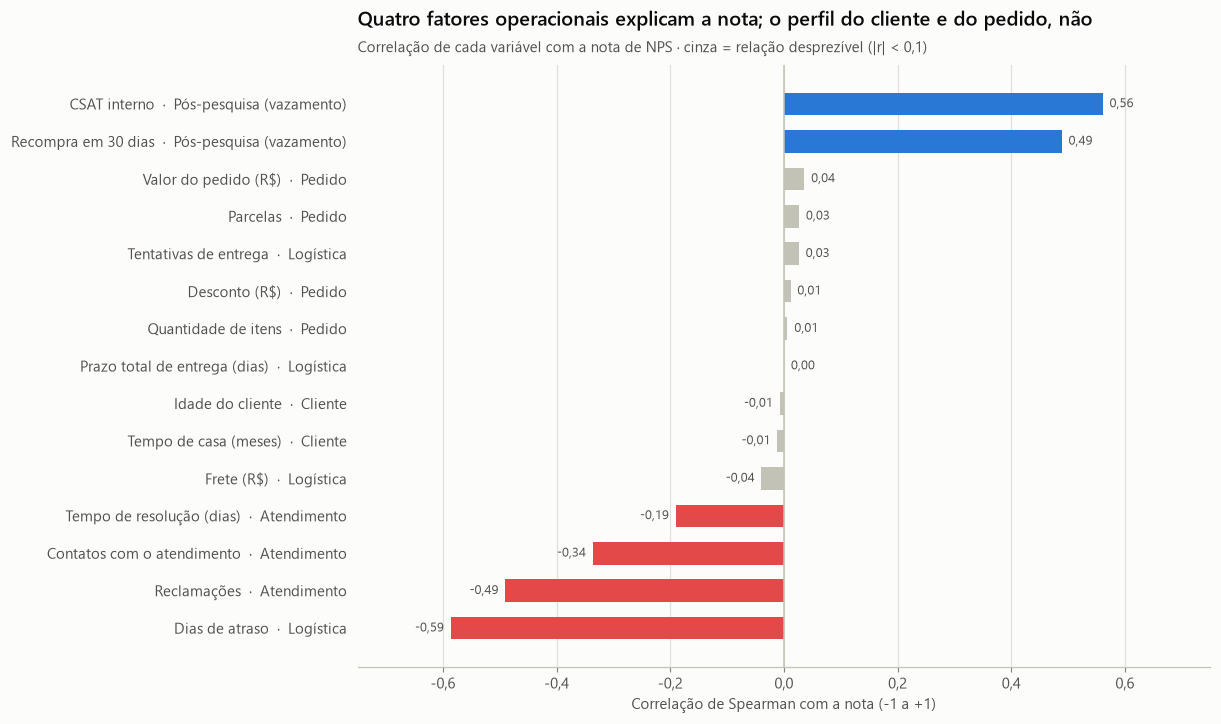

In [5]:
fig = viz.plot_correlation_bars(
    correlation_table["correlacao"],
    title="Quatro fatores operacionais explicam a nota; o perfil do cliente e do pedido, não",
    subtitle="Correlação de cada variável com a nota de NPS · cinza = relação desprezível (|r| < 0,1)",
)
viz.save_figure(fig, "03_fatores_correlacao.png")
plt.show()

> **Leitura para a operação:** a satisfação depende de **quatro fatores, todos operacionais**:
>
> | Fator | Área | Força da relação |
> |---|---|---|
> | Dias de atraso na entrega | Logística | **forte** (-0,59) |
> | Número de reclamações | Atendimento / Produto | **forte** (-0,49) |
> | Contatos com o atendimento | Atendimento | moderada (-0,34) |
> | Tempo para resolver o problema | Atendimento | fraca (-0,19) |
>
> **Não fazem diferença:** prazo total de entrega, tentativas de entrega, frete, valor do pedido,
> desconto, parcelas, idade, região e tempo de casa (todos com correlação entre -0,04 e +0,04).
>
> O CSAT interno e a recompra em 30 dias também andam junto com o NPS, mas são **consequência** da
> satisfação, não causa. Não são alavancas de gestão e não podem entrar no modelo (notebook 03).

*Nota técnica:* com 2.500 linhas, até relações minúsculas podem ter p-valor abaixo de 0,05 (é o
caso do frete, r = -0,04). Por isso o critério de relevância usado é o **tamanho** da correlação
(|r| ≥ 0,1), e não apenas o p-valor. Significância estatística não é o mesmo que importância para
o negócio.

### 1.1 Prazo total x atraso: o cliente pune a promessa quebrada, não a espera

Esse é o achado mais contraintuitivo da base. Os dois gráficos usam a mesma escala.

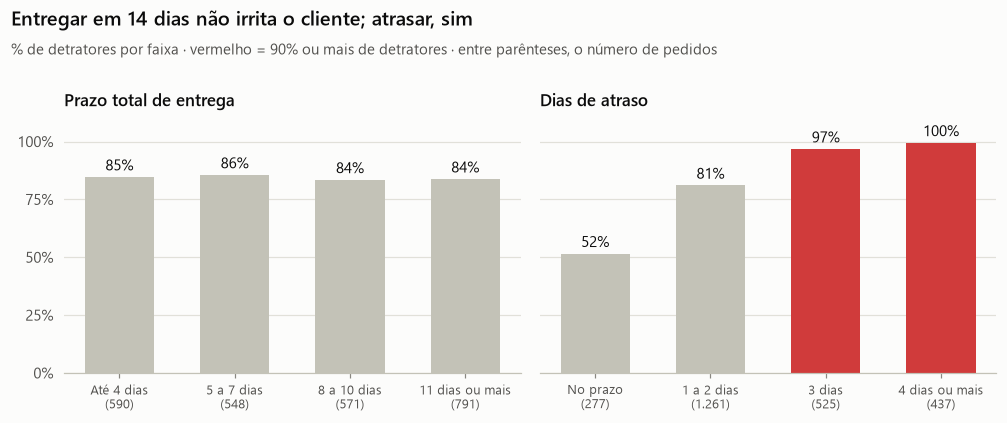

-80.2 <- NPS de entregas em até 4 dias
-79.8 <- NPS de entregas em 11 dias ou mais


In [6]:
fig = viz.plot_detractor_panels(
    df,
    panels=[("delivery_time_range", "Prazo total de entrega"), ("delay_range", "Dias de atraso")],
    title="Entregar em 14 dias não irrita o cliente; atrasar, sim",
    subtitle="% de detratores por faixa · vermelho = 90% ou mais de detratores · entre parênteses, o número de pedidos",
    highlight_above=90,
)
viz.save_figure(fig, "04_prazo_vs_atraso.png")
plt.show()

print(data_prep.nps_index(df.loc[df["delivery_time_days"] <= 4, "nps_score"]), "<- NPS de entregas em até 4 dias")
print(data_prep.nps_index(df.loc[df["delivery_time_days"] >= 11, "nps_score"]), "<- NPS de entregas em 11 dias ou mais")

> **Leitura para a operação:** quem recebeu em até 4 dias e quem esperou 11 dias ou mais têm
> **praticamente o mesmo NPS** (cerca de -80). Já o atraso leva a taxa de detratores de 52% (no
> prazo) para quase 100%. Os dados sugerem que **prometer um prazo maior e cumprir é melhor do que
> prometer um prazo curto e atrasar**. Revisar o prazo exibido no site para algo realista é uma
> ação de custo baixo.

## 2. O que mais gera detratores?

Agora olhamos a **taxa de detratores** em cada faixa dos quatro fatores críticos.

In [7]:
driver_ranges = {
    "delay_range": "Dias de atraso",
    "complaints_range": "Reclamações",
    "contacts_range": "Contatos com o atendimento",
    "resolution_range": "Tempo de resolução",
}
pd.concat({label: viz.detractor_rate_table(df, column) for column, label in driver_ranges.items()})

pedidos  nota_media  \
Dias de atraso             No prazo            277        6.90   
                           1 a 2 dias         1261        5.10   
                           3 dias              525        3.40   
                           4 dias ou mais      437        2.00   
Reclamações                0 a 1               145        7.90   
                           2                   277        6.10   
                           3 a 4              1107        4.50   
                           5 ou mais           971        3.20   
Contatos com o atendimento Nenhum              554        5.50   
                           1                   816        4.70   
                           2                   640        4.10   
                           3 ou mais           490        2.90   
Tempo de resolução         Até 2 dias          629        5.00   
                           3 a 5 dias          619        4.50   
                           6 a 8 dias          637        4.20   
                           9 dias ou mais      615        3.80   

                                           pct_detratores  pct_promotores  \
Dias de atraso             No prazo                 51.60           18.10   
                           1 a 2 dias               81.10            4.50   
                           3 dias                   96.80            0.60   
                           4 dias ou mais           99.50            0.00   
Reclamações                0 a 1                    28.30           24.10   
                           2                        65.30           11.20   
                           3 a 4                    86.10            3.60   
                           5 ou mais                96.20            0.40   
Contatos com o atendimento Nenhum                   70.80           10.30   
                           1                        83.90            4.40   
                           2                        88.60            2.20   
                           3 ou mais                94.90            0.60   
Tempo de resolução         Até 2 dias               77.70            7.50   
                           3 a 5 dias               82.60            5.20   
                           6 a 8 dias               86.80            3.00   
                           9 dias ou mais           90.40            2.00   

                                             nps  
Dias de atraso             No prazo       -33.60  
                           1 a 2 dias     -76.60  
                           3 dias         -96.20  
                           4 dias ou mais -99.50  
Reclamações                0 a 1           -4.10  
                           2              -54.20  
                           3 a 4          -82.50  
                           5 ou mais      -95.80  
Contatos com o atendimento Nenhum         -60.50  
                           1              -79.50  
                           2              -86.40  
                           3 ou mais      -94.30  
Tempo de resolução         Até 2 dias     -70.30  
                           3 a 5 dias     -77.40  
                           6 a 8 dias     -83.80  
                           9 dias ou mais -88.50

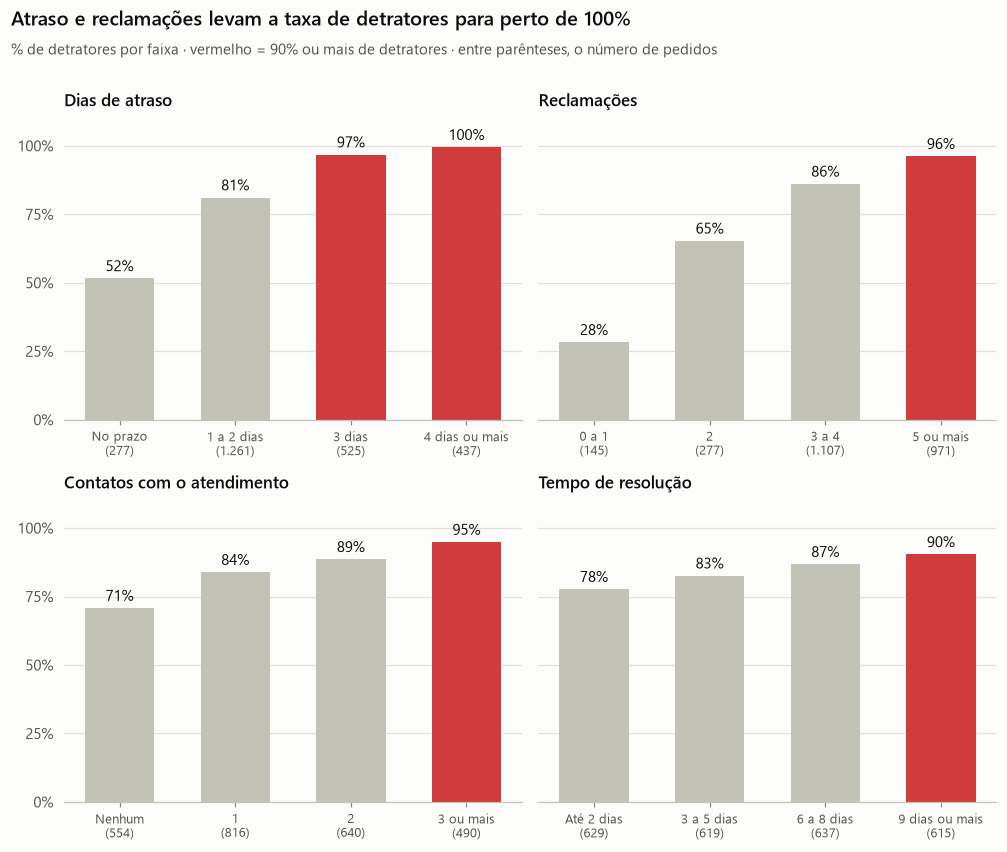

In [8]:
fig = viz.plot_detractor_panels(
    df,
    panels=list(driver_ranges.items()),
    title="Atraso e reclamações levam a taxa de detratores para perto de 100%",
    subtitle="% de detratores por faixa · vermelho = 90% ou mais de detratores · entre parênteses, o número de pedidos",
    highlight_above=90,
    ncols=2,
)
viz.save_figure(fig, "05_detratores_por_fator.png")
plt.show()

### 2.1 Quanto cada problema pesa no total de detratores

Um fator pode ser grave mas raro, ou moderado mas muito frequente. A tabela abaixo cruza as duas
coisas: **quantos pedidos têm o problema** e **quantos detratores ele explica**.

In [9]:
problems = {
    "Atraso de 3 dias ou mais": df["delivery_delay_days"] >= 3,
    "5 reclamações ou mais": df["complaints_count"] >= 5,
    "3 contatos ou mais com o atendimento": df["customer_service_contacts"] >= 3,
    "Resolução em 9 dias ou mais": df["resolution_time_days"] >= 9,
}
is_detractor = df["is_detractor"] == 1

exposure = pd.DataFrame(
    {
        "% dos pedidos com o problema": {name: mask.mean() * 100 for name, mask in problems.items()},
        "% dos detratores com o problema": {name: mask[is_detractor].mean() * 100 for name, mask in problems.items()},
        "taxa de detratores COM o problema": {name: df.loc[mask, "is_detractor"].mean() * 100 for name, mask in problems.items()},
        "taxa de detratores SEM o problema": {name: df.loc[~mask, "is_detractor"].mean() * 100 for name, mask in problems.items()},
    }
)
any_major_problem = problems["Atraso de 3 dias ou mais"] | problems["5 reclamações ou mais"] | problems["3 contatos ou mais com o atendimento"]
print(f"Detratores com pelo menos um dos três primeiros problemas: {any_major_problem[is_detractor].mean():.0%}")
exposure.round(1)

Detratores com pelo menos um dos três primeiros problemas: 70%


,% dos pedidos com o problema,% dos detratores com o problema,taxa de detratores COM o problema,taxa de detratores SEM o problema
Atraso de 3 dias ou mais,38.50,44.70,98.00,75.80
5 reclamações ou mais,38.80,44.30,96.20,76.80
3 contatos ou mais com o atendimento,19.60,22.00,94.90,81.80
Resolução em 9 dias ou mais,24.60,26.40,90.40,82.40


> **Leitura para a operação:**
>
> - **O atraso é o maior gerador de detratores.** 38,5% dos pedidos chegam com 3 dias ou mais de
>   atraso, e nesse grupo **98% viram detratores**. Quase metade (45%) de todos os detratores da
>   base passou por esse atraso.
> - **Reclamações em excesso** (5 ou mais) têm peso parecido: 39% dos pedidos, 96% de detratores.
> - **Contatos repetidos** (3 ou mais) atingem menos pedidos (20%), mas também levam a 95% de
>   detratores.
> - **7 em cada 10 detratores** passaram por pelo menos um desses três problemas.

### 2.2 Os problemas se somam

O que acontece quando o mesmo pedido atrasa **e** obriga o cliente a procurar o atendimento?

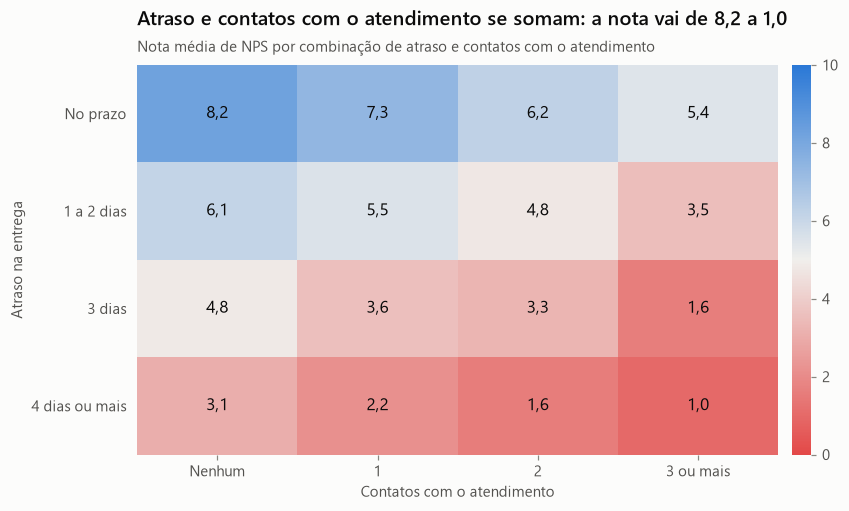

In [10]:
score_by_delay_and_contacts = df.pivot_table(
    index="delay_range", columns="contacts_range", values="nps_score", aggfunc="mean", observed=True
)
fig = viz.plot_heatmap(
    score_by_delay_and_contacts,
    title="Atraso e contatos com o atendimento se somam: a nota vai de 8,2 a 1,0",
    subtitle="Nota média de NPS por combinação de atraso e contatos com o atendimento",
    xlabel="Contatos com o atendimento",
    ylabel="Atraso na entrega",
)
viz.save_figure(fig, "06_mapa_atraso_contatos.png")
plt.show()

> **Leitura para a operação:** o pedido que chega no prazo e não precisa de atendimento tem nota
> média **8,2**, perto de virar promotor. O pedido que atrasa 4 dias ou mais e gera 3 contatos tem
> nota média **1,0**. Cada problema puxa a nota para baixo **por conta própria**, e eles se
> acumulam. Na prática: **quando um pedido atrasa, o atendimento precisa agir antes que o cliente
> tenha de ligar**, senão o estrago dobra.

## 3. Existe um "ponto de ruptura" na experiência do cliente?

Para não escolher os cortes "no olho", usamos uma **árvore de decisão rasa** (um algoritmo que
testa todos os cortes possíveis de uma variável e escolhe os que mais separam notas altas de notas
baixas). Os cortes encontrados foram usados para criar as faixas da análise.

In [11]:
def find_breakpoints(column: str, depth: int = 2) -> list[float]:
    """Cortes da variável onde a nota média muda mais de patamar."""
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=50, random_state=config.RANDOM_STATE)
    tree.fit(df[[column]], df["nps_score"])
    return sorted(round(float(t), 1) for t in tree.tree_.threshold if t != -2)


pd.Series(
    {config.FEATURE_LABELS[column]: find_breakpoints(column) for column in config.OPERATIONAL_DRIVERS},
    name="cortes encontrados",
)

Dias de atraso                [0.5, 2.5, 3.5]
Reclamações                   [1.5, 2.5, 4.5]
Contatos com o atendimento    [0.5, 2.5, 3.5]
Tempo de resolução (dias)     [1.5, 3.5, 7.5]
Name: cortes encontrados, dtype: object

Os cortes 0,5 / 2,5 / 3,5 no atraso significam os grupos **0 dias | 1 a 2 dias | 3 dias | 4 ou mais**.
O gráfico abaixo mostra, dia a dia, como detratores, neutros e promotores se dividem.

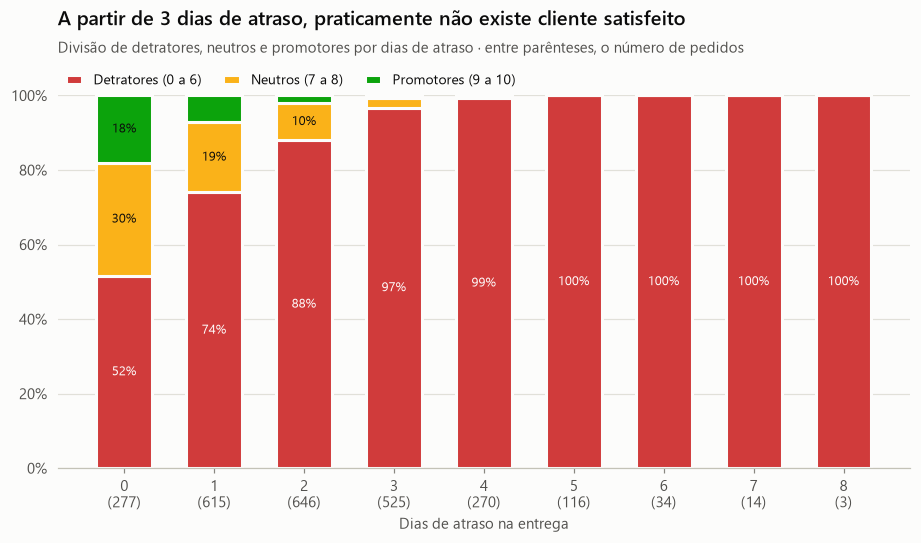

,pedidos,nota_media,pct_detratores,pct_promotores,nps
delivery_delay_days,,,,,
0,277,6.90,51.60,18.10,-33.60
1,615,5.50,74.00,7.20,-66.80
2,646,4.60,87.90,2.00,-85.90
3,525,3.40,96.80,0.60,-96.20
4,270,2.40,99.30,0.00,-99.30
5,116,1.50,100.00,0.00,-100.00
6,34,1.10,100.00,0.00,-100.00
7,14,0.30,100.00,0.00,-100.00
8,3,0.00,100.00,0.00,-100.00


In [12]:
fig = viz.plot_category_mix(
    df,
    "delivery_delay_days",
    title="A partir de 3 dias de atraso, praticamente não existe cliente satisfeito",
    subtitle="Divisão de detratores, neutros e promotores por dias de atraso · entre parênteses, o número de pedidos",
    xlabel="Dias de atraso na entrega",
)
viz.save_figure(fig, "07_ruptura_atraso.png")
plt.show()

viz.detractor_rate_table(df, "delivery_delay_days")

In [13]:
# Teste estatístico: a nota de quem atrasou até 2 dias é diferente da nota de quem atrasou 3 ou mais?
up_to_two_days = df.loc[df["delivery_delay_days"] <= 2, "nps_score"]
three_or_more = df.loc[df["delivery_delay_days"] >= 3, "nps_score"]
mann_whitney = stats.mannwhitneyu(up_to_two_days, three_or_more)
print(f"Nota média até 2 dias de atraso: {up_to_two_days.mean():.2f} | 3 dias ou mais: {three_or_more.mean():.2f}")
print(f"Mann-Whitney: p-valor = {mann_whitney.pvalue:.1e}")

chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(df["delay_range"], df["nps_category"]))
print(f"Qui-quadrado (faixa de atraso x categoria NPS): p-valor = {p_value:.1e}")

Nota média até 2 dias de atraso: 5.38 | 3 dias ou mais: 2.78
Mann-Whitney: p-valor = 1.2e-140
Qui-quadrado (faixa de atraso x categoria NPS): p-valor = 1.1e-81


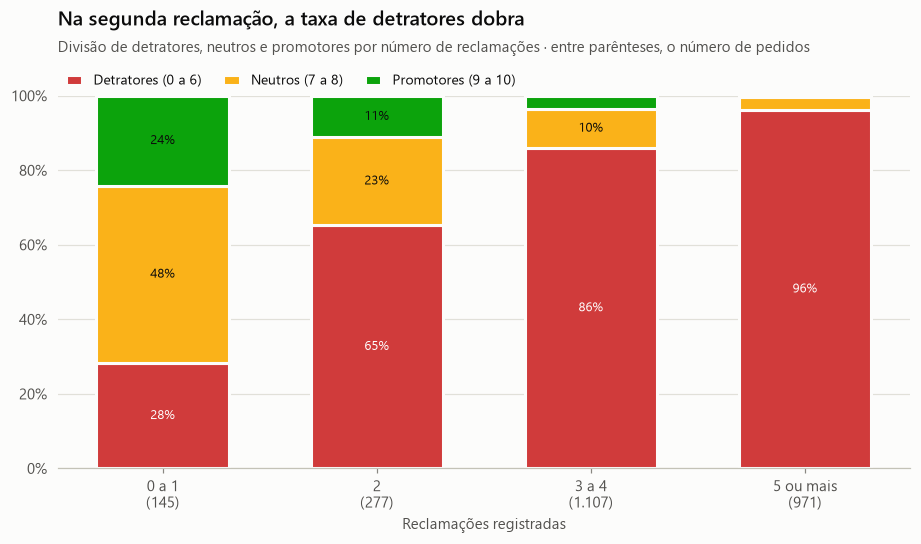

Pedidos com 2 reclamações ou mais: 94%


In [14]:
fig = viz.plot_category_mix(
    df,
    "complaints_range",
    title="Na segunda reclamação, a taxa de detratores dobra",
    subtitle="Divisão de detratores, neutros e promotores por número de reclamações · entre parênteses, o número de pedidos",
    xlabel="Reclamações registradas",
)
viz.save_figure(fig, "08_ruptura_reclamacoes.png")
plt.show()

print(f"Pedidos com 2 reclamações ou mais: {(df['complaints_count'] >= 2).mean():.0%}")

> **Leitura para a operação:** existem dois pontos de ruptura claros.
>
> 1. **Terceiro dia de atraso.** No prazo, 18% dos clientes são promotores. Com 1 dia de atraso,
>    7%. Com 2 dias, 2%. **Com 3 dias, 97% são detratores e quase nenhum é promotor; com 4 dias ou
>    mais, 100% são detratores.** Hoje **38,5% dos pedidos** já estão depois desse ponto. A meta
>    operacional mais clara da análise é: **nenhum pedido pode passar de 2 dias de atraso**.
> 2. **Segunda reclamação.** Com até 1 reclamação, 28% são detratores; com 2, a taxa sobe para
>    65%. Mas 94% dos clientes já têm 2 reclamações ou mais registradas, o que reforça a dúvida
>    levantada no notebook 01 sobre o que essa coluna realmente conta.
>
> Contatos com o atendimento e tempo de resolução **não têm um degrau**: pioram a nota aos poucos,
> a cada contato ou dia a mais.
>
> Os testes estatísticos confirmam que a diferença entre "até 2 dias" e "3 dias ou mais" de atraso
> não é obra do acaso (p-valor praticamente zero).

## 4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?

Primeiro olhamos o **perfil**: quem o cliente é e o que ele comprou.

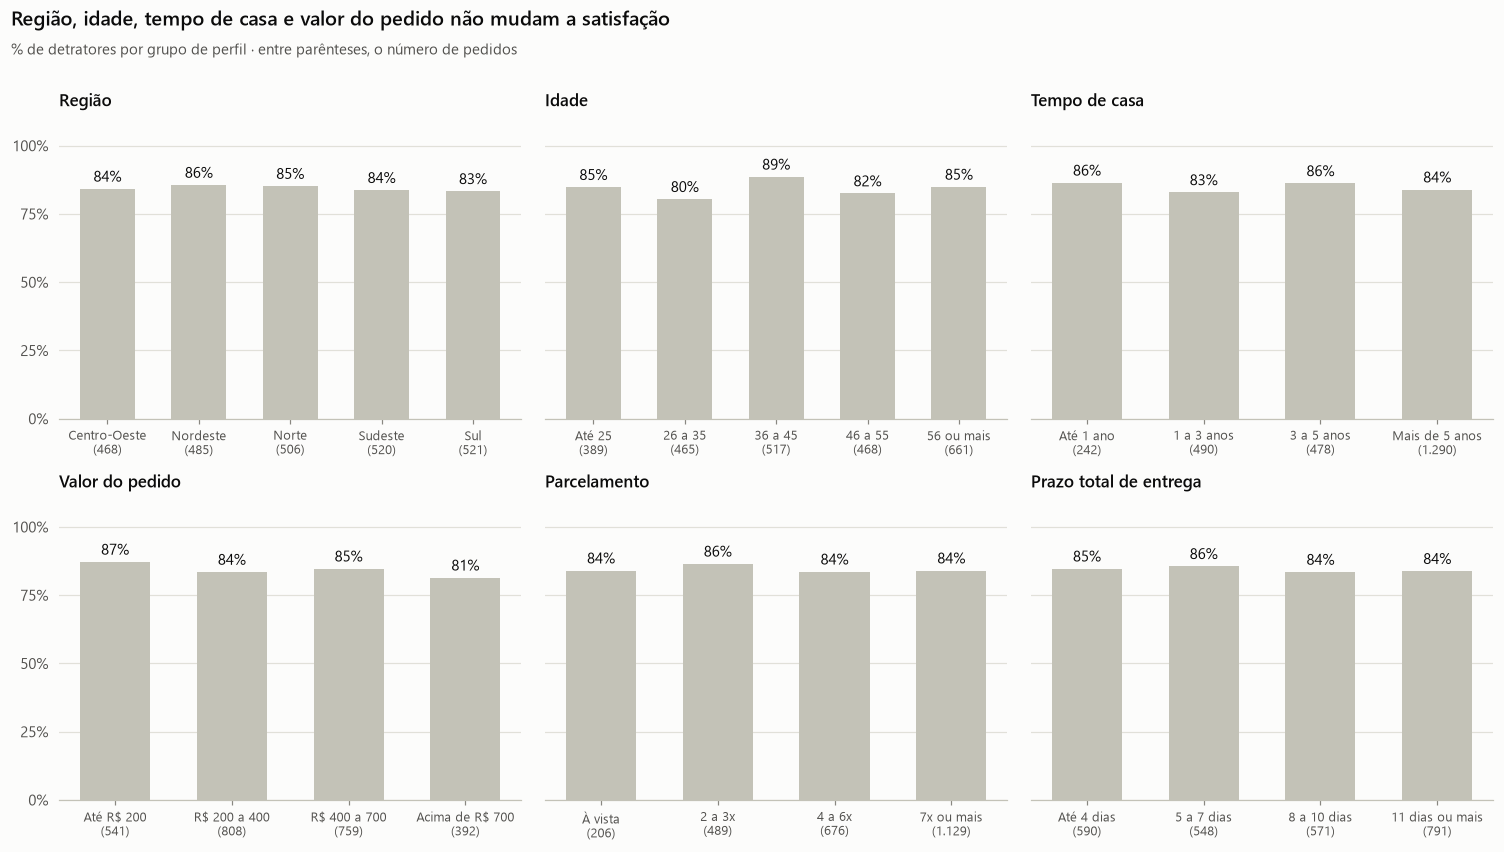

In [15]:
profile_panels = [
    ("customer_region", "Região"),
    ("age_range", "Idade"),
    ("tenure_range", "Tempo de casa"),
    ("order_value_range", "Valor do pedido"),
    ("installments_range", "Parcelamento"),
    ("delivery_time_range", "Prazo total de entrega"),
]
fig = viz.plot_detractor_panels(
    df,
    panels=profile_panels,
    title="Região, idade, tempo de casa e valor do pedido não mudam a satisfação",
    subtitle="% de detratores por grupo de perfil · entre parênteses, o número de pedidos",
    ncols=3,
)
viz.save_figure(fig, "09_perfil_cliente.png")
plt.show()

In [16]:
# Kruskal-Wallis: as notas dos grupos vêm da mesma distribuição? (p-valor > 0,05 = sem diferença)
kruskal_rows = []
for column, label in profile_panels:
    groups = [group["nps_score"].to_numpy() for _, group in df.groupby(column, observed=True)]
    result = stats.kruskal(*groups)
    kruskal_rows.append({"perfil": label, "p_valor": round(result.pvalue, 3),
                         "diferença estatística?": "sim" if result.pvalue < 0.05 else "não"})
pd.DataFrame(kruskal_rows).set_index("perfil")

,p_valor,diferença estatística?
perfil,,
Região,0.50,não
Idade,0.11,não
Tempo de casa,0.20,não
Valor do pedido,0.07,não
Parcelamento,0.28,não
Prazo total de entrega,0.43,não


Nenhum dos recortes de perfil mostra diferença estatística. **O "tipo de cliente" que importa não é
definido por quem ele é, mas pelo que aconteceu com o pedido dele.** Por isso agrupamos os clientes
pela experiência vivida, usando os pontos de ruptura encontrados acima:

- **Boa:** até 1 dia de atraso, até 2 reclamações e no máximo 1 contato com o atendimento;
- **Ruim:** 3 dias ou mais de atraso ou 5 reclamações ou mais;
- **Intermediária:** todo o resto.

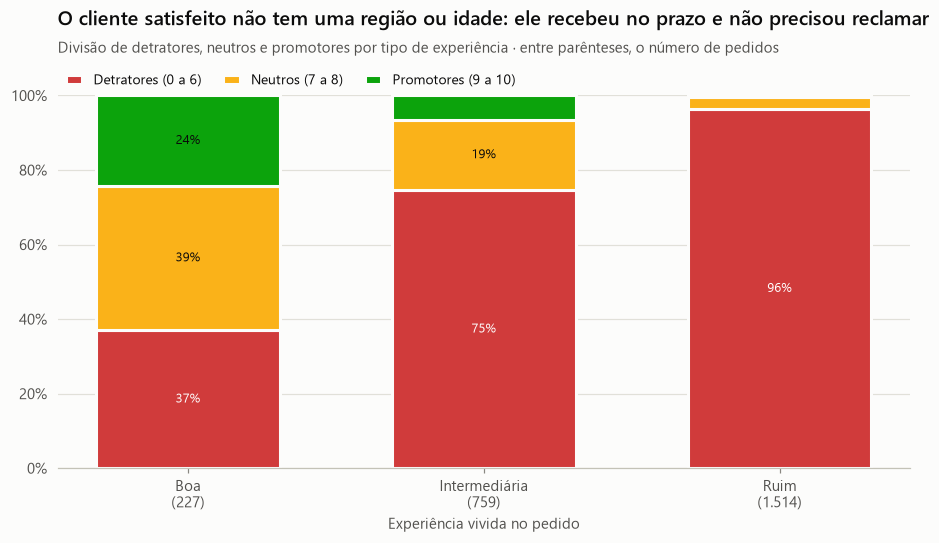

,pedidos,nota_media,pct_detratores,pct_promotores,nps
experience_profile,,,,,
Boa,227,7.50,37.00,24.20,-12.80
Intermediária,759,5.60,74.60,6.50,-68.10
Ruim,1514,3.30,96.40,0.40,-96.00


In [17]:
fig = viz.plot_category_mix(
    df,
    "experience_profile",
    title="O cliente satisfeito não tem uma região ou idade: ele recebeu no prazo e não precisou reclamar",
    subtitle="Divisão de detratores, neutros e promotores por tipo de experiência · entre parênteses, o número de pedidos",
    xlabel="Experiência vivida no pedido",
)
viz.save_figure(fig, "10_perfil_experiencia.png")
plt.show()

viz.detractor_rate_table(df, "experience_profile")

> **Leitura para a operação:**
>
> - **NPS mais alto:** clientes com experiência **Boa** (227 pedidos, 9% da base). Nota média 7,5,
>   24% de promotores, mais de cinco vezes a média da base.
> - **NPS mais baixo:** clientes com experiência **Ruim** (1.514 pedidos, 61% da base). Nota média
>   3,3 e 96% de detratores.
> - **Região, idade, tempo de casa, valor do pedido e parcelamento não fazem diferença.** Não
>   adianta criar campanhas de satisfação por segmento de perfil: o que muda a nota é a operação.

## 5. Por que isso importa: NPS e recompra

A base traz se o cliente voltou a comprar em até 30 dias. Isso permite medir o valor de um promotor.

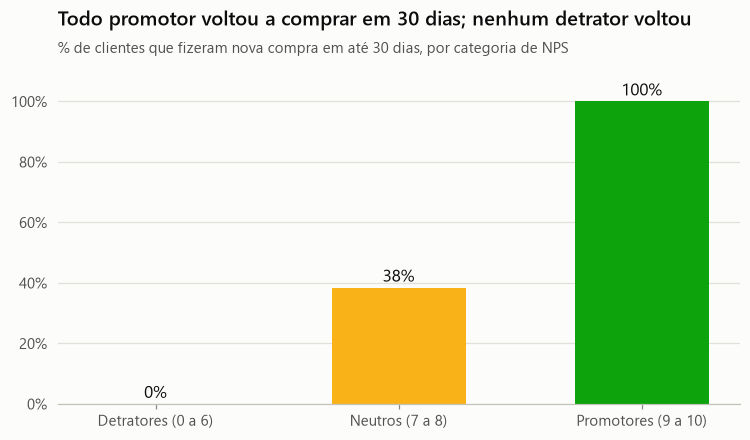

,taxa_recompra,clientes_que_recompraram,clientes
nps_category,,,
detrator,0.00,0,2109
neutro,38.40,108,281
promotor,100.00,110,110


In [18]:
repurchase = df.groupby("nps_category", observed=True)["repeat_purchase_30d"].agg(
    taxa_recompra="mean", clientes_que_recompraram="sum", clientes="size"
)
repurchase["taxa_recompra"] = repurchase["taxa_recompra"] * 100

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(repurchase))
ax.bar(positions, repurchase["taxa_recompra"], width=0.55,
       color=[viz.CATEGORY_COLORS[category] for category in repurchase.index])
for position, value in zip(positions, repurchase["taxa_recompra"]):
    ax.text(position, value + 2, viz.fmt_percent(value), ha="center", fontsize=11, color=viz.INK)
ax.set_xticks(positions, [viz.CATEGORY_LABELS[category] for category in repurchase.index])
ax.set_ylim(0, 112)
ax.yaxis.set_major_formatter(viz.percent_axis)
viz.set_titles(ax, "Todo promotor voltou a comprar em 30 dias; nenhum detrator voltou",
               "% de clientes que fizeram nova compra em até 30 dias, por categoria de NPS")
viz.save_figure(fig, "11_recompra_por_categoria.png")
plt.show()
repurchase.round(1)

> **Leitura para a operação:** **100% dos promotores** recompraram em 30 dias, contra **38% dos
> neutros** e **nenhum detrator**. Nesta base, cada cliente que passa de detrator para promotor
> é uma recompra praticamente garantida. Esse é o argumento financeiro para investir na operação.
>
> *Cuidado:* a recompra acontece **depois** da pesquisa. Ela mostra o valor do NPS, mas não pode
> ser usada para prever o NPS (seria usar o futuro para prever o passado).

## 6. CSAT interno x NPS: dois termômetros diferentes

In [19]:
csat_relations = df[["nps_score"] + config.OPERATIONAL_DRIVERS].corrwith(df["csat_internal_score"], method="spearman")
csat_relations.index = csat_relations.index.map(config.FEATURE_LABELS)
csat_relations.round(2).rename("correlação com o CSAT interno")

Nota NPS                      0.56
Dias de atraso               -0.46
Reclamações                  -0.38
Contatos com o atendimento   -0.36
Tempo de resolução (dias)    -0.74
Name: correlação com o CSAT interno, dtype: float64

> **Leitura para a operação:** o CSAT interno está ligado principalmente ao **tempo de resolução**
> (-0,74), enquanto o NPS está ligado principalmente ao **atraso** (-0,59). O CSAT mede a
> qualidade do atendimento; o NPS mede a promessa de entrega. Os dois se complementam e nenhum
> substitui o outro. Como o CSAT também é uma pesquisa de satisfação, ele fica fora do modelo
> preditivo.

## Resumo para o gerente de operações

1. **A satisfação está muito baixa:** NPS -80, com 84 detratores para cada 4 promotores.
2. **Quatro fatores explicam a nota, todos operacionais:** atraso na entrega, reclamações, contatos
   com o atendimento e tempo de resolução, nessa ordem de importância.
3. **O maior gerador de detratores é o atraso.** 38,5% dos pedidos atrasam 3 dias ou mais, e 98%
   desses clientes viram detratores.
4. **Ponto de ruptura: o terceiro dia de atraso.** Daí em diante, praticamente nenhum cliente fica
   satisfeito. Meta sugerida: nenhum pedido acima de 2 dias de atraso.
5. **Prazo longo não é problema, prazo descumprido é.** Prometer prazos realistas reduz atraso sem
   precisar entregar mais rápido.
6. **Os problemas se somam:** atraso que vira ligação para o atendimento derruba a nota de 8,2
   para 1,0. Avisar o cliente antes que ele precise ligar corta esse efeito.
7. **Perfil não importa, experiência sim:** região, idade, tempo de casa e valor do pedido não
   mudam a nota. Clientes com experiência boa têm 24% de promotores; com experiência ruim, 0,4%.
8. **Promotor volta a comprar:** 100% dos promotores recompraram em 30 dias; nenhum detrator voltou.

O notebook 03 transforma esses achados em um modelo que estima a nota de cada pedido **antes** da
pesquisa, para que a operação aja a tempo.